# The Inverted Pendulum and the ASE/ACE Actor–Critic in Python, Line by Line

**Reinforcement Lab · CSIT843A Lecture 5** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/reinforcementlearning/code-pendulum.html**

A complete, runnable notebook that simulates the cart-pole, tests hand-written rules, cuts the state into 162 boxes and trains the 1983 actor–critic of Barto, Sutton and Anderson from nothing but a −1 at each failure. Only NumPy and Matplotlib are needed. Hover over (or tap) any line of code to see what it does.

**You will learn to:**

1. Simulate the cart-pole from its equations of motion
2. See why the obvious hand-written rule fails
3. Turn four continuous numbers into one of 162 boxes
4. Implement the ASE/ACE actor–critic with signed eligibility traces
5. Read what the actor and the critic have learned

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Import the libraries

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ececec"

**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   A Jupyter setting (not Python): sharper plots on high-resolution screens.
2. `import numpy as np`  
   NumPy: arrays, maths and random numbers.
3. `import matplotlib.pyplot as plt`  
   Matplotlib: every chart.
4. `plt.rcParams["figure.figsize"] = (7, 4)`  
   Default figure size (width, height) in inches.
5. `plt.rcParams["axes.spines.top"] = False` …  
   A cleaner look: hide the top and right borders of every chart.
6. `plt.rcParams["axes.grid"] = True` …  
   Light grid lines make values easier to read.

## 2. The cart-pole

Four numbers describe the system: cart position `x`, cart velocity `xd`, pole angle `th` (radians, 0 = upright) and angular velocity `thd`. Every 0.02 s the controller pushes with +10 N or −10 N. These equations are the **world model**; the learner will never see them.

In [2]:
G, M_CART, M_POLE, L_HALF, FORCE, TAU = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02

def step(state, push_right):
    x, xd, th, thd = state
    f = FORCE if push_right else -FORCE
    cos, sin, total = np.cos(th), np.sin(th), M_CART + M_POLE
    temp = (f + M_POLE * L_HALF * thd**2 * sin) / total
    thacc = (G * sin - cos * temp) / (L_HALF * (4 / 3 - M_POLE * cos**2 / total))
    xacc = temp - M_POLE * L_HALF * thacc * cos / total
    return (x + TAU * xd, xd + TAU * xacc, th + TAU * thd, thd + TAU * thacc)

def failed(state):
    return abs(state[0]) > 2.4 or abs(state[2]) > np.radians(12)

s, t = (0.0, 0.0, np.radians(1), 0.0), 0
while not failed(s):
    s, t = step(s, t % 2 == 0), t + 1
print(f"alternating pushes: fell after {t} steps ({t * TAU:.2f} s)")

alternating pushes: fell after 42 steps (0.84 s)


**Line by line**

1. `G, M_CART, M_POLE, L_HALF, FORCE, TAU = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02`  
   The constants of Barto, Sutton & Anderson (1983), also used by Gymnasium.
2. `def step(state, push_right):`  
   Move the system forward by one time step (0.02 s).
3. `x, xd, th, thd = state`  
   Unpack the four numbers.
4. `f = FORCE if push_right else -FORCE`  
   The only thing the controller decides.
5. `cos, sin, total = np.cos(th), np.sin(th), M_CART + M_POLE`  
   Short names for the formulas below.
6. `temp = (f + M_POLE * L_HALF * thd**2 * sin) / total` …  
   Equations of motion: the pole's angular acceleration…
7. `xacc = temp - M_POLE * L_HALF * thacc * cos / total`  
   …and the cart's acceleration.
8. `return (x + TAU * xd, xd + TAU * xacc, th + TAU * thd, thd + TAU * thacc)`  
   One small Euler step forward.
9. `def failed(state):` …  
   Failure: pole more than 12° from vertical, or cart off the 2.4 m track.
10. `s, t = (0.0, 0.0, np.radians(1), 0.0), 0`  
   Start with the pole at 1° and do nothing clever:
11. `while not failed(s):` …  
   push left and right alternately until the pole falls.
12. `print(f"alternating pushes: fell after {t} steps ({t * TAU:.2f} s)")`  
   Left alone, it falls in well under a second.

## 3. Hand-written rules

The obvious rule, "push towards the side the pole leans", overcorrects. Adding the angular velocity, reacting to where the pole is *going*, keeps it up.

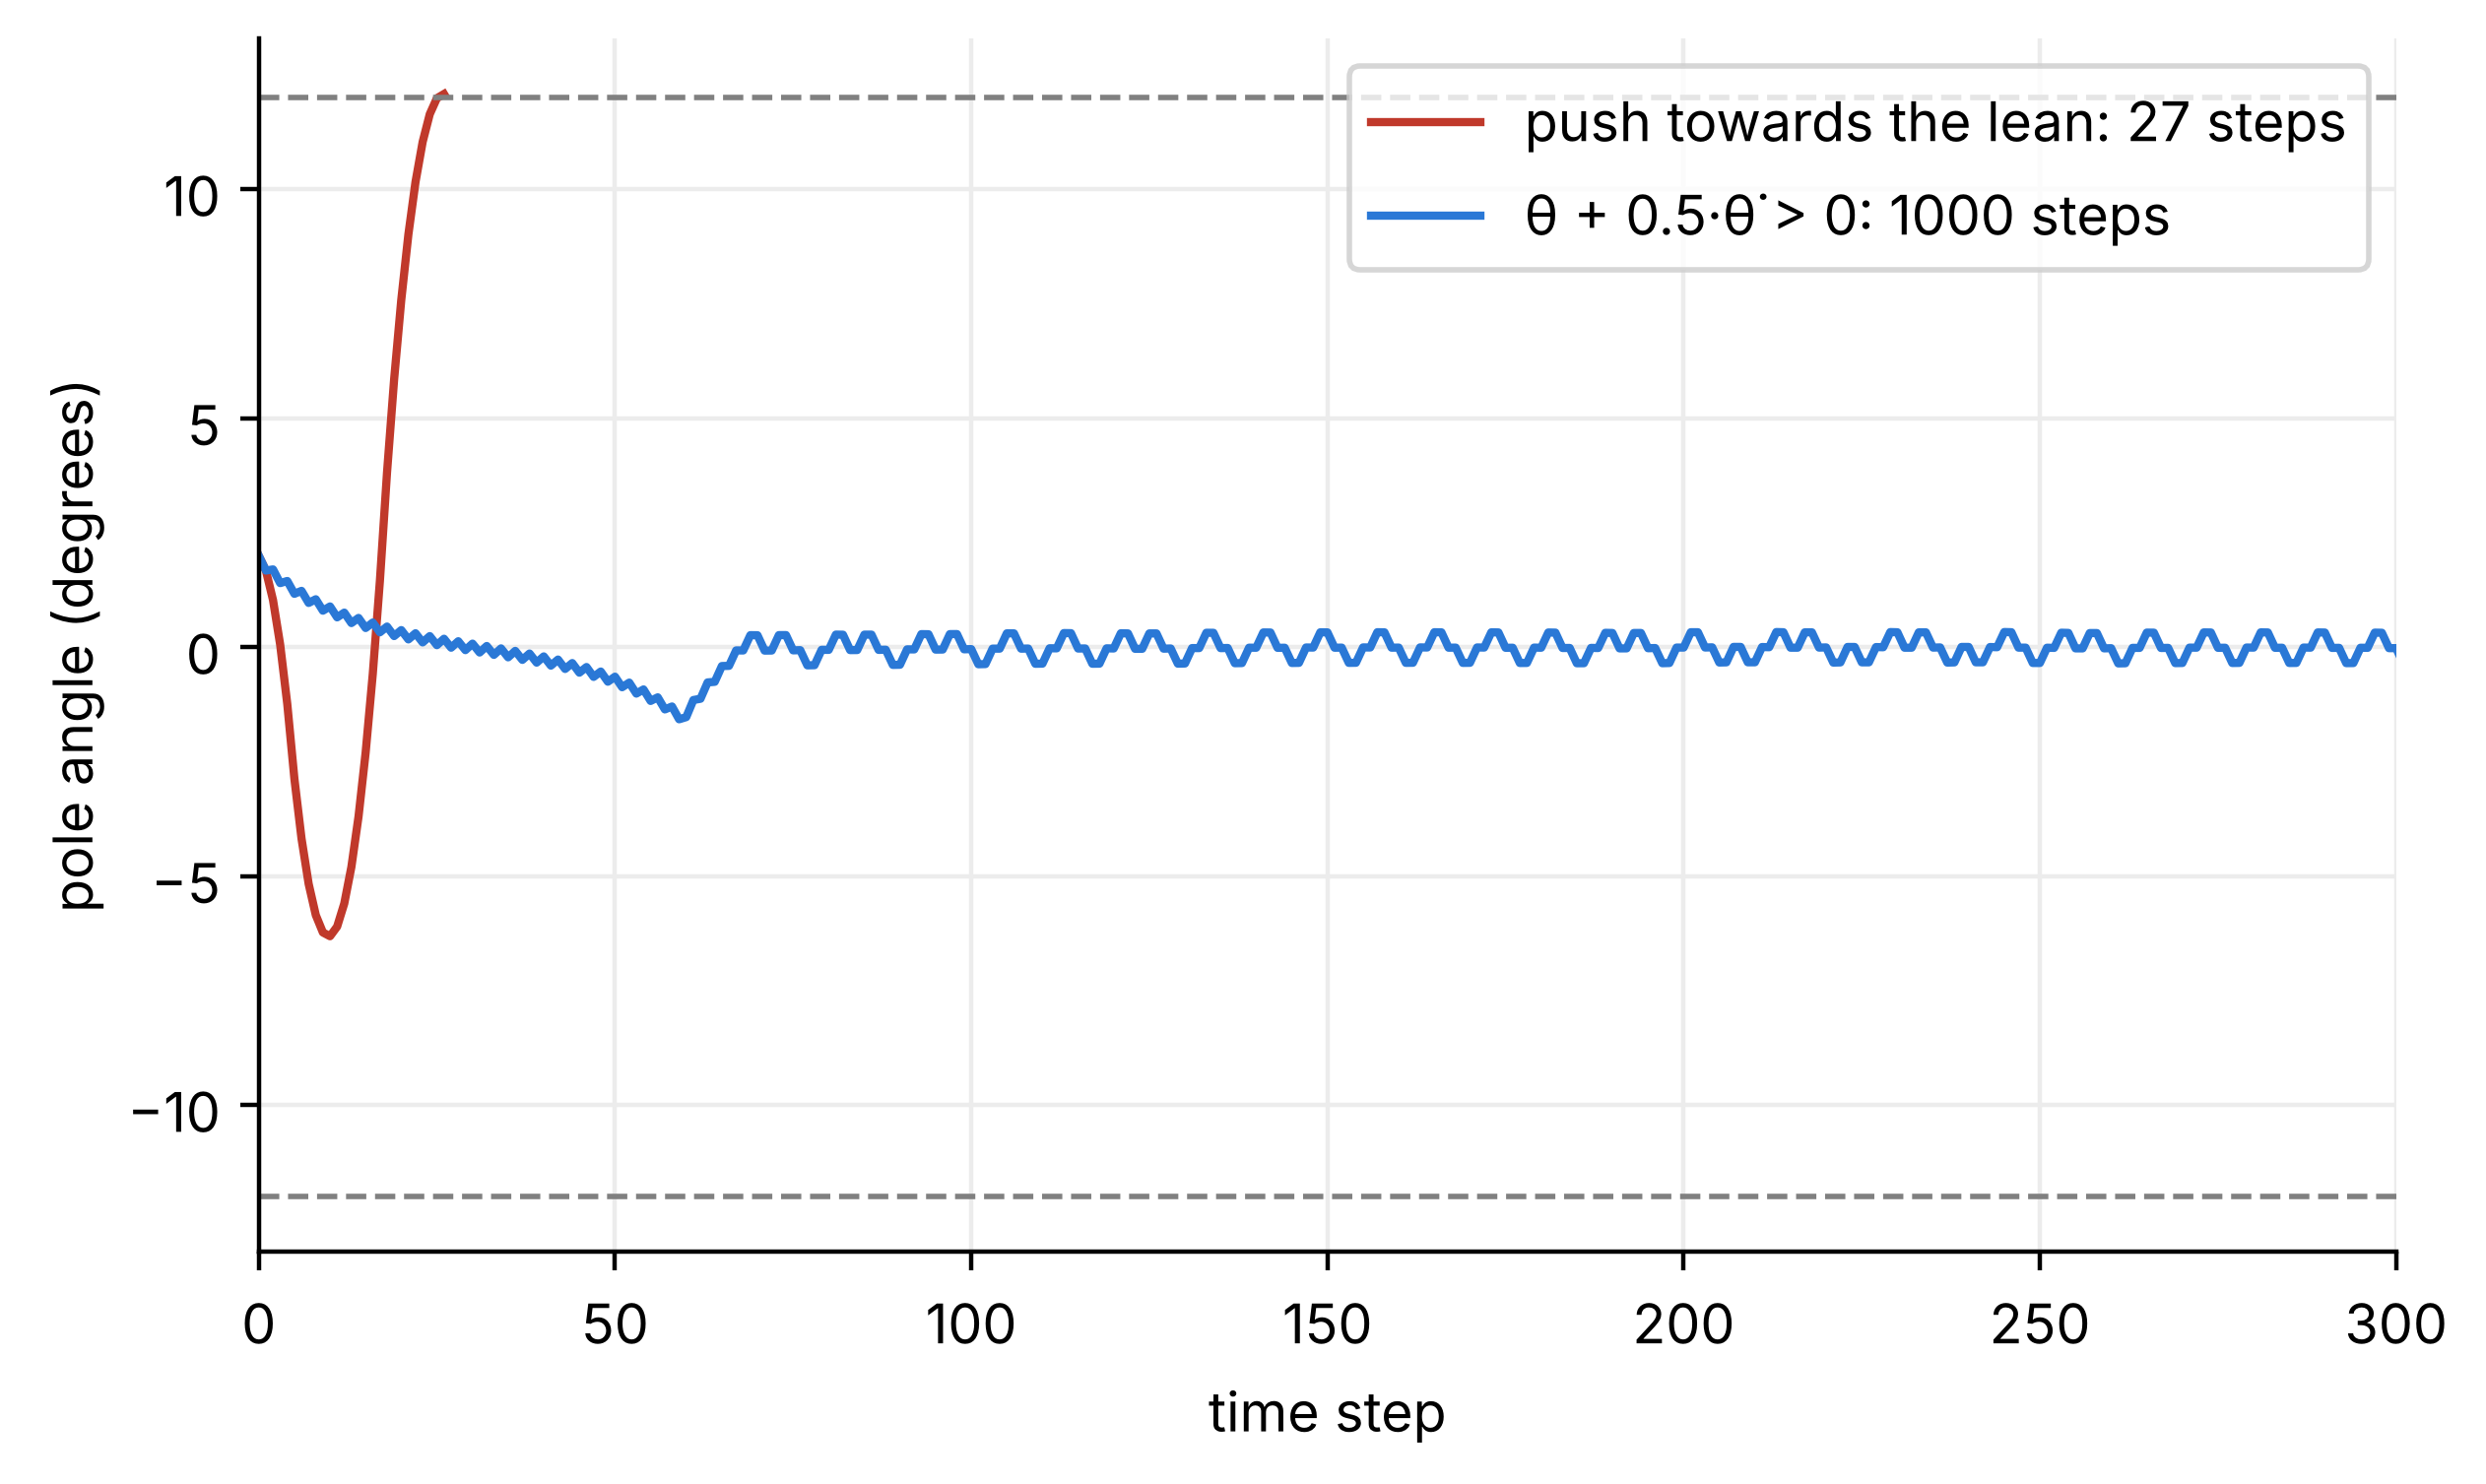

In [3]:
def run_rule(rule, theta0_deg=2.0, max_steps=1000):
    s, angles = (0.0, 0.0, np.radians(theta0_deg), 0.0), []
    for _ in range(max_steps):
        s = step(s, rule(s))
        angles.append(np.degrees(s[2]))
        if failed(s): break
    return angles

lean = lambda s: s[2] > 0
lean_and_speed = lambda s: s[2] + 0.5 * s[3] > 0
for rule, name, col in [(lean, "push towards the lean", "#c0392b"), (lean_and_speed, "θ + 0.5·θ̇ > 0", "#2a78d6")]:
    a = run_rule(rule)
    plt.plot(a, color=col, label=f"{name}: {len(a)} steps")
plt.axhline(12, ls="--", color="grey", lw=1); plt.axhline(-12, ls="--", color="grey", lw=1)
plt.xlim(0, 300); plt.xlabel("time step"); plt.ylabel("pole angle (degrees)"); plt.legend()
plt.show()

**Line by line**

1. `def run_rule(rule, theta0_deg=2.0, max_steps=1000):` …  
   Run one trial with a fixed rule; return the angle history.
2. `s = step(s, rule(s))` …  
   The rule looks at the state and decides the push.
3. `if failed(s): break` …  
   Stop at failure.
4. `lean = lambda s: s[2] > 0`  
   Rule 1: push right if the pole leans right.
5. `lean_and_speed = lambda s: s[2] + 0.5 * s[3] > 0`  
   Rule 2: also look at how fast it is turning.
6. `for rule, name, col in [(lean, "push towards the lean", "#c0392b"), (lean_and_speed, "θ + 0.5·θ̇ > 0", "#2a78d6")]:` …  
   Plot both.
7. `plt.axhline(12, ls="--", color="grey", lw=1); plt.axhline(-12, ls="--", color="grey", lw=1)` …  
   The failure limits.
8. `plt.show()`  
   Rule 1's swings grow until it falls; rule 2 stays near vertical.

## 4. The boxes

Each variable is cut into a few intervals: 3 × 3 × 6 × 3 = **162 boxes**. The learner is told only the box number.

In [4]:
def get_box(state):
    x, xd, th, thd = state
    bx = 0 if x < -0.8 else 1 if x < 0.8 else 2
    bxd = 0 if xd < -0.5 else 1 if xd < 0.5 else 2
    edges = np.radians([-6, -1, 0, 1, 6])
    bt = int(np.searchsorted(edges, th, side="right"))
    btd = 0 if thd < np.radians(-50) else 1 if thd < np.radians(50) else 2
    return bx + 3 * bxd + 9 * bt + 54 * btd

print("upright and still:", get_box((0, 0, 0.0, 0)), "  leaning 8° right and falling right fast:", get_box((0, 0, np.radians(8), 1.5)))

upright and still: 85   leaning 8° right and falling right fast: 157


**Line by line**

1. `def get_box(state):` …  
   The decoder: four numbers → one of 162 boxes (the classic numbering).
2. `bx = 0 if x < -0.8 else 1 if x < 0.8 else 2`  
   Cart position: left, middle, right.
3. `bxd = 0 if xd < -0.5 else 1 if xd < 0.5 else 2`  
   Cart velocity: moving left, slow, moving right.
4. `edges = np.radians([-6, -1, 0, 1, 6])`  
   Angle: finer near the vertical.
5. `bt = int(np.searchsorted(edges, th, side="right"))`  
   Which of the six angle intervals (0–5).
6. `btd = 0 if thd < np.radians(-50) else 1 if thd < np.radians(50) else 2`  
   Angular velocity: falling left fast, slow, falling right fast.
7. `return bx + 3 * bxd + 9 * bt + 54 * btd`  
   Combine the four interval numbers into one box number 0–161.
8. `print("upright and still:", get_box((0, 0, 0.0, 0)), "  leaning 8° right and falling right fast:", get_box((0, 0, np.radians(8), 1.5)))`  
   Two examples.

## 5. The ASE/ACE actor–critic

Each box has a **weight** `w` (the actor's preference: positive pushes right) and a **prediction** `v` (the critic: 0 = safe, −1 = failure near). The actor's eligibility `e` is **signed**: it remembers which way the box pushed recently. The critic's TD error `r_hat` tells the actor whether to repeat or reverse what it did.

solved after 89 failures


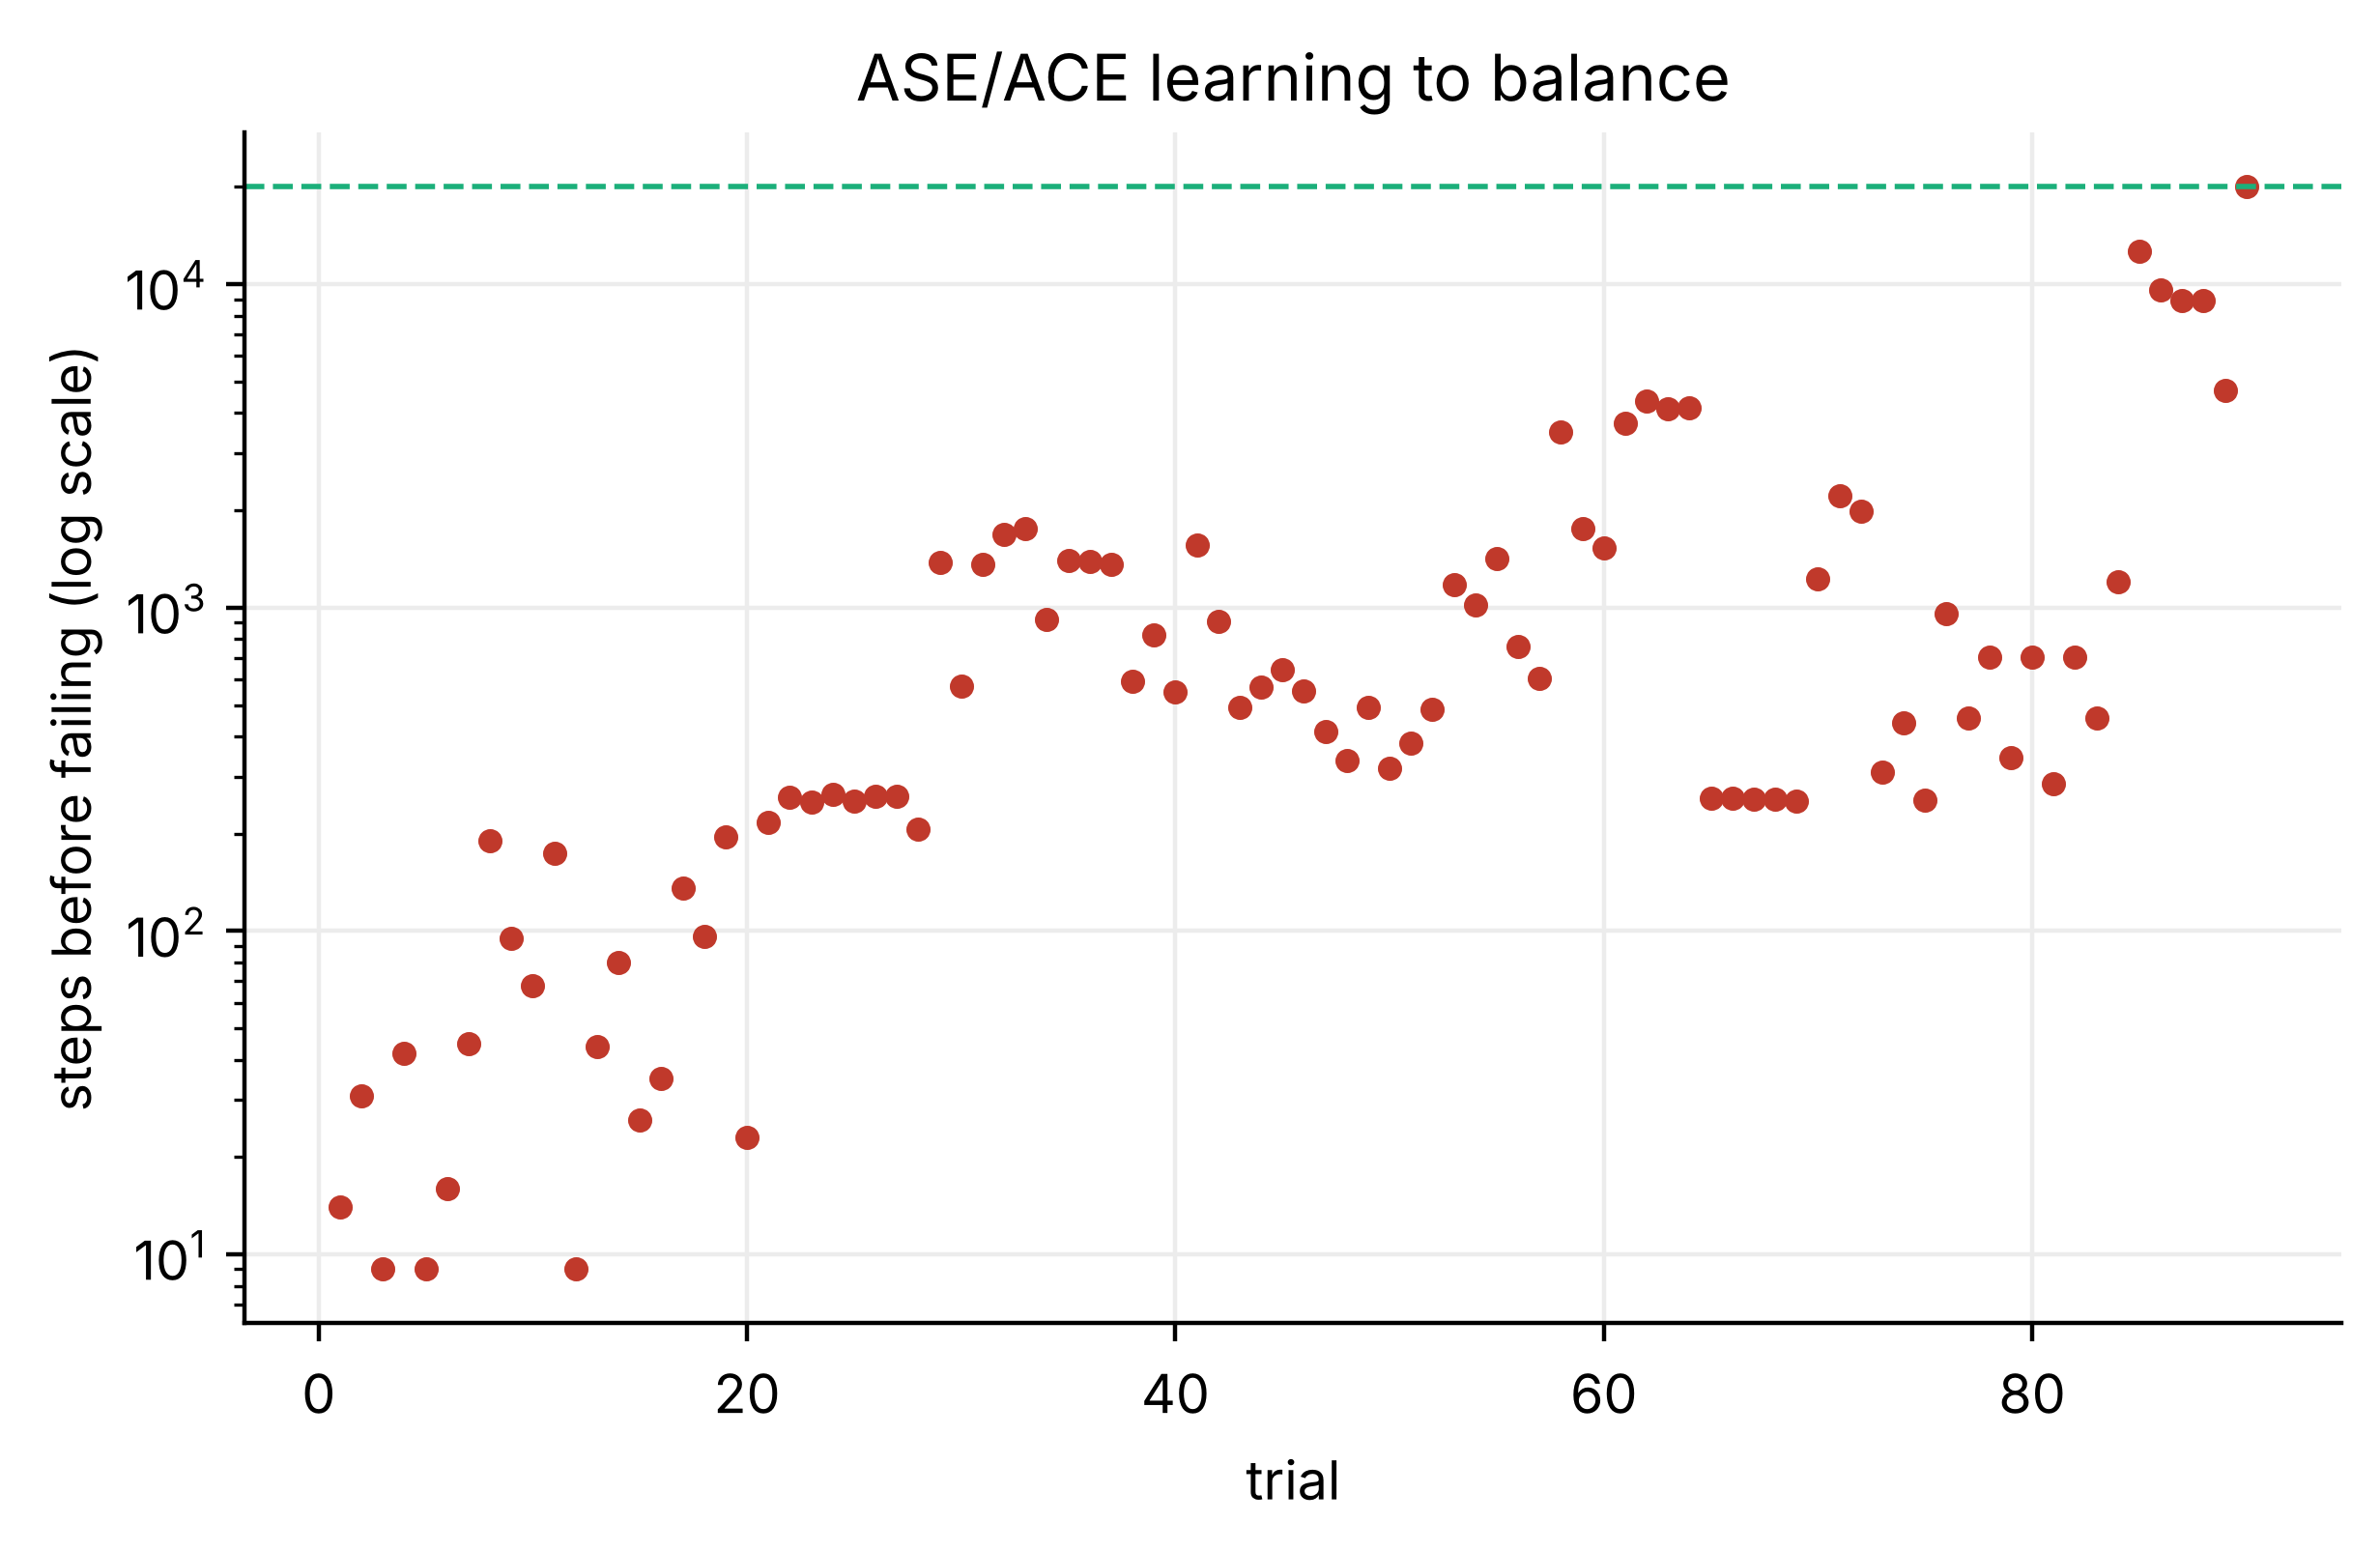

In [5]:
def train(seed, critic=True, max_trials=400, solved=20000):
    rng = np.random.default_rng(seed)
    alpha, beta, gamma, lam, lam_v = 1000.0, 0.5, 0.95, 0.9, 0.8
    w, v = np.zeros(162), np.zeros(162)
    lengths = []
    for trial in range(max_trials):
        s, e, xbar = (0.0, 0.0, 0.0, 0.0), np.zeros(162), np.zeros(162)
        box, t = get_box(s), 0
        while True:
            p_right = 1 / (1 + np.exp(-np.clip(w[box], -50, 50)))
            y = 1.0 if rng.random() < p_right else 0.0
            e[box] += (1 - lam) * (y - 0.5)
            xbar[box] += 1 - lam_v
            s = step(s, y == 1.0); t += 1
            fail = failed(s)
            r = -1.0 if fail else 0.0
            new_box = None if fail else get_box(s)
            p_new = 0.0 if fail else v[new_box]
            r_hat = (r + gamma * p_new - v[box]) if critic else r
            w += alpha * r_hat * e
            if critic: v += beta * r_hat * xbar
            e *= lam; xbar *= lam_v
            box = new_box
            if fail or t >= solved: break
        lengths.append(t)
        if t >= solved: break
    return lengths, w, v

lengths, w, v = train(seed=13)
print(f"solved after {len(lengths) - 1} failures" if lengths[-1] >= 20000 else "not solved in 400 trials")
plt.semilogy(range(1, len(lengths) + 1), lengths, "o", ms=3.5, color="#c0392b")
plt.axhline(20000, ls="--", color="#1baf7a", lw=1)
plt.xlabel("trial"); plt.ylabel("steps before failing (log scale)"); plt.title("ASE/ACE learning to balance")
plt.show()

**Line by line**

1. `def train(seed, critic=True, max_trials=400, solved=20000):` …  
   The ASE/ACE actor–critic. Returns the trial lengths and the learned tables.
2. `alpha, beta, gamma, lam, lam_v = 1000.0, 0.5, 0.95, 0.9, 0.8`  
   The parameters of the 1983 paper.
3. `w, v = np.zeros(162), np.zeros(162)`  
   Actor weights and critic predictions, all zero.
4. `lengths = []`  
   Steps survived in each trial.
5. `for trial in range(max_trials):`  
   One trial = from upright until the pole falls.
6. `s, e, xbar = (0.0, 0.0, 0.0, 0.0), np.zeros(162), np.zeros(162)` …  
   Reset the cart and both traces.
7. `p_right = 1 / (1 + np.exp(-np.clip(w[box], -50, 50)))`  
   σ(w): the probability of pushing right in this box.
8. `y = 1.0 if rng.random() < p_right else 0.0`  
   1 = right, 0 = left.
9. `e[box] += (1 - lam) * (y - 0.5)`  
   Signed eligibility: + if it pushed right, − if left.
10. `xbar[box] += 1 - lam_v`  
   The critic's trace has no sign.
11. `s = step(s, y == 1.0); t += 1` …  
   Apply the push.
12. `r = -1.0 if fail else 0.0` …  
   The only external signal: −1 at failure.
13. `p_new = 0.0 if fail else v[new_box]`  
   After a failure there is no next box.
14. `r_hat = (r + gamma * p_new - v[box]) if critic else r`  
   The internal reinforcement = the TD error. Without a critic: the raw r.
15. `w += alpha * r_hat * e`  
   Every box: Δw = α · r̂ · e. Sign of r̂ × sign of e = the direction of the correction.
16. `if critic: v += beta * r_hat * xbar`  
   The critic learns its predictions by TD(0).
17. `e *= lam; xbar *= lam_v` …  
   All traces fade.
18. `if fail or t >= solved: break` …  
   End of the trial.
19. `if t >= solved: break` …  
   Balanced for 400 s: solved.
20. `lengths, w, v = train(seed=13)` …  
   Train once.
21. `plt.semilogy(range(1, len(lengths) + 1), lengths, "o", ms=3.5, color="#c0392b")`  
   Steps per trial, on a log scale.
22. `plt.axhline(20000, ls="--", color="#1baf7a", lw=1)` …  
   The "solved" line.

## 6. What did it learn?

A slice through the 162 boxes: cart in the middle and slow. Columns are the pole angle, rows the angular velocity.

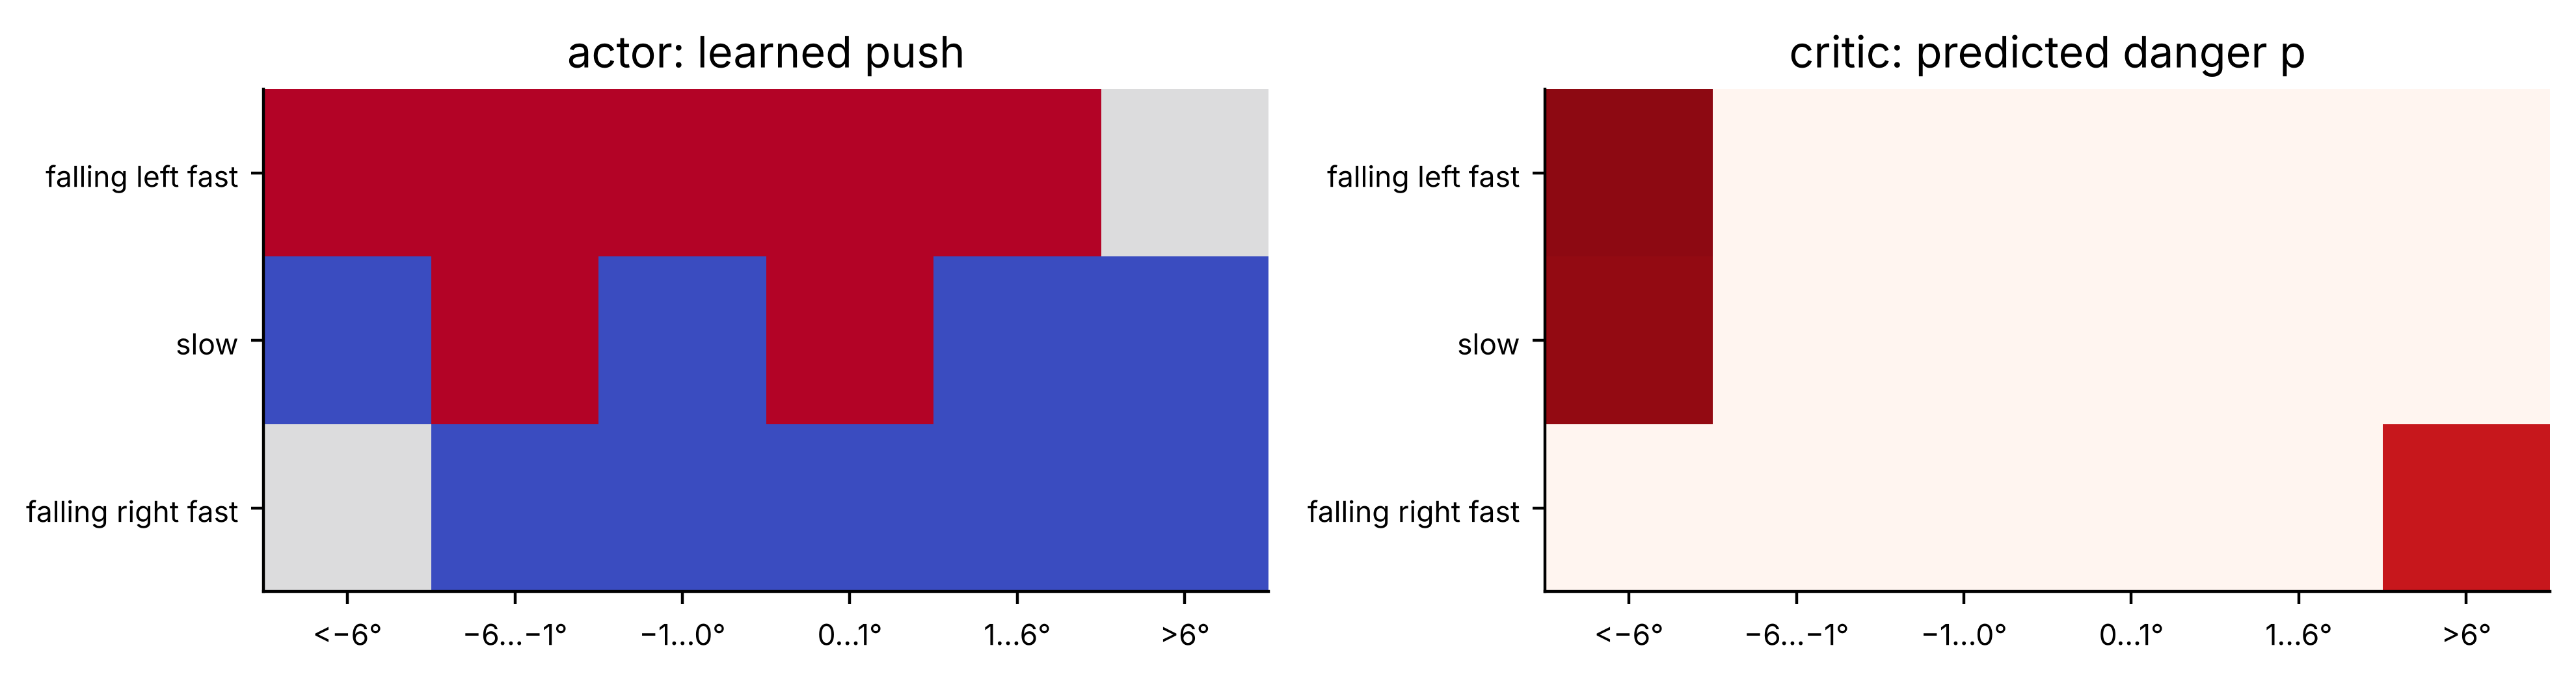

In [6]:
angles = ["<−6°", "−6…−1°", "−1…0°", "0…1°", "1…6°", ">6°"]
speeds = ["falling left fast", "slow", "falling right fast"]
idx = np.array([[1 + 3 * 1 + 9 * bt + 54 * btd for bt in range(6)] for btd in range(3)])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].imshow(np.sign(w[idx]), cmap="coolwarm_r", vmin=-1, vmax=1)
axes[0].set_title("actor: learned push")
axes[1].imshow(v[idx], cmap="Reds_r", vmin=-0.6, vmax=0)
axes[1].set_title("critic: predicted danger p")
for ax in axes:
    ax.set_xticks(range(6)); ax.set_xticklabels(angles, fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels(speeds, fontsize=8); ax.grid(False)
plt.tight_layout(); plt.show()

**Line by line**

1. `angles = ["<−6°", "−6…−1°", "−1…0°", "0…1°", "1…6°", ">6°"]`  
   Column labels.
2. `speeds = ["falling left fast", "slow", "falling right fast"]`  
   Row labels.
3. `idx = np.array([[1 + 3 * 1 + 9 * bt + 54 * btd for bt in range(6)] for btd in range(3)])`  
   The box numbers of the slice (bx = 1, bxd = 1).
4. `fig, axes = plt.subplots(1, 2, figsize=(10, 3))`  
   Two heat maps side by side.
5. `axes[0].imshow(np.sign(w[idx]), cmap="coolwarm_r", vmin=-1, vmax=1)` …  
   Actor: blue = push right, red = push left (white: never visited).
6. `axes[1].imshow(v[idx], cmap="Reds_r", vmin=-0.6, vmax=0)` …  
   Critic: darker = more dangerous.
7. `for ax in axes:` …  
   Labels on both maps.
8. `plt.tight_layout(); plt.show()`  
   Falling fast → push in the direction of the fall: the hand-written rule 2, found from failures alone.

## 7. Does the critic matter?

Run the actor alone (raw failure signal) and the full actor–critic with ten seeds each.

In [7]:
for critic in (False, True):
    results = []
    for seed in range(1, 11):
        L, _, _ = train(seed, critic=critic)
        results.append(len(L) - 1 if L[-1] >= 20000 else None)
    ok = [x for x in results if x is not None]
    name = "actor + critic" if critic else "actor alone   "
    print(f"{name}: solved {len(ok)}/10" + (f", median {int(np.median(ok))} failures" if ok else ""))

actor alone   : solved 0/10


actor + critic: solved 9/10, median 64 failures


**Line by line**

1. `for critic in (False, True):` …  
   Compare the two versions.
2. `for seed in range(1, 11):` …  
   Ten different random seeds.
3. `results.append(len(L) - 1 if L[-1] >= 20000 else None)` …  
   Failures needed, or None if not solved in 400 trials.
4. `print(f"{name}: solved {len(ok)}/10" + (f", median {int(np.median(ok))} failures" if ok else ""))`  
   The critic makes the difference.

## 8. Try it yourself

1. Change `lam` (the actor's trace decay) to 0.5 and to 0.99. How does it change the number of failures needed?
2. Start every trial from a small random state instead of upright. Does it still learn?
3. Implement Q-learning on the same boxes (a table `Q[162, 2]`, reward −1 at failure, no ε) and compare it with the actor–critic.
4. Change the reward: −1 at failure **and** a small penalty for large angles. Is the trained controller calmer?